# ch02_2. 신경망 형식의 선형회귀

## 개요

- 직접 만든 가중치 $W$와 편향 $b$를 `nn.Linear` 구조로 바꿉니다.

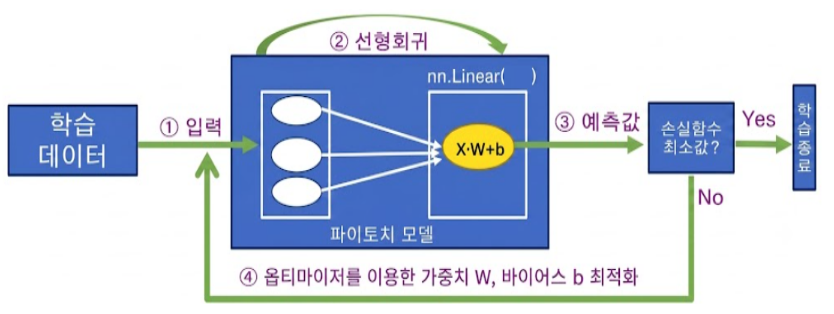

- 같은 학습 함수를 기본 예제와 센서 보정 예제에 재사용합니다.

## 1. 학습 데이터 준비

`nn.Linear(1, 1)`은 데이터 하나당 입력 특성 1개를 받습니다.

따라서 데이터 모양은 다음과 같이 구성합니다.

$$
[\text{데이터 수},\ \text{입력 특성 수}]
$$

이번 데이터는 3개이며, 각 데이터의 입력 특성은 1개입니다.

- 입력 shape: `(3, 1)`
- 출력 shape: `(3, 1)`

In [ ]:
#01. 학습데이터 준비
import torch
from torch import nn

torch.manual_seed(42)

x_train = torch.tensor([[1.0], [2.0], [3.0]])
y_train = torch.tensor([[1.0], [2.0], [3.0]])

print("x_train:")
print(x_train)
print("shape:", x_train.shape)

print()
print("y_train:")
print(y_train)
print("shape:", y_train.shape)

x_train:
tensor([[1.],
        [2.],
        [3.]])
shape: torch.Size([3, 1])

y_train:
tensor([[1.],
        [2.],
        [3.]])
shape: torch.Size([3, 1])


## 2. 직접 계산에서 신경망 구조로 바꾸기

$$
\hat{y}=Wx+b
$$

- `nn.Linear(1, 1)`이 $W$와 $b$를 내부에서 생성하고 관리합니다.
- ReLU(렐루, 음수를 0으로 바꾸는 활성화 함수)는 사용하지 않습니다.
- 같은 선형회귀를 신경망 형식으로 표현합니다.

## 3. `nn.Module`로 모델 정의하기

모델 클래스에는 두 부분만 작성합니다.

- `__init__()` : 사용할 계층 정의
- `forward()` : 입력이 모델을 통과하는 과정 정의

In [ ]:
#03. nn.Module을 상속받아서 새로운 클래스 생성
class LinearRegressionModel(nn.Module):  
    def __init__(self):
        super().__init__()

        # 입력 1개 → 출력 1개
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        # 내부에서 y_hat = W*x + b 계산
        return self.linear(x)


model = LinearRegressionModel()
print(model)

LinearRegressionModel(
  (linear): Linear(in_features=1, out_features=1, bias=True)
)


## 4. 모델 안의 가중치와 편향 확인

`nn.Linear` 내부에는 학습 대상인 가중치와 편향이 들어 있습니다.

- `weight`: 직선의 기울기 $W$
- `bias`: 직선의 절편 $b$

처음에는 임의의 값으로 시작하고, 학습하면서 데이터에 맞게 변경됩니다.

In [ ]:
#04. 모델 안의 가중치와 편향 확인
print("초기 W:", model.linear.weight.item())
print("초기 b:", model.linear.bias.item())

print()
for name, parameter in model.named_parameters():
    print(name, parameter.shape)

## 5. 손실함수와 최적화 도구

- `nn.MSELoss()`는 예측값과 실제값의 평균제곱오차를 계산합니다.
- `torch.optim.SGD()`는 Loss가 감소하도록 모델 매개변수를 갱신합니다.
- `model.parameters()`는 모델 내부의 모든 학습 대상을 가져옵니다.

학습 순서는 와 같습니다.

$$
\text{Forward}
\rightarrow
\text{Loss}
\rightarrow
\text{Backward}
\rightarrow
\text{Update}
$$

## 6. 재사용 가능한 학습 함수

학습 코드를 한 번만 작성한 뒤 여러 데이터에 재사용합니다.

함수 내부에서 다음 작업을 반복합니다.

1. `model(x)`로 예측
2. Loss 계산
3. 이전 기울기 초기화
4. 역전파
5. 매개변수 갱신

In [ ]:
#06. 함수 (재사용 가능한 학습)
def train_model(model, x, y, learning_rate=0.01, epochs=2000):
    loss_function = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate,)

    first_loss = None

    for epoch in range(epochs):
        # 1. 순전파
        prediction = model(x)

        # 2. 손실 계산
        loss = loss_function(prediction, y)

        if epoch == 0:
            first_loss = loss.item()

        # 3. 이전 기울기 초기화
        optimizer.zero_grad()

        # 4. 역전파
        loss.backward()

        # 5. 매개변수 갱신
        optimizer.step()

    return first_loss, loss.item()

## 7. 기본 선형회귀 모델 학습

학습 데이터는 $y=x$ 관계입니다.

따라서 학습이 끝나면 다음 값에 가까워집니다.

$$
W \approx 1,\qquad b \approx 0
$$

In [ ]:
#07. 모델 학습
torch.manual_seed(42)

model = LinearRegressionModel()

first_loss, final_loss = train_model(
    model,
    x_train,
    y_train,
)

print("학습된 W:", model.linear.weight.item())
print("학습된 b:", model.linear.bias.item())
print("Loss 변화:", first_loss, "→", final_loss)

## 8. 새로운 값 예측

학습이 끝난 뒤에는 `model.eval()`로 평가 모드로 전환합니다.

예측 과정에서는 기울기 계산이 필요하지 않으므로 `torch.no_grad()`를 사용합니다.

In [ ]:
x_new = torch.tensor([[2.5], [5.0]])

model.eval()

with torch.no_grad():
    y_new = model(x_new)

print("새 입력:")
print(x_new[:, 0])

print()
print("예측값:")
print(y_new[:, 0])

## 9. 실무 예제: 센서 입력 전압 보정

입력 전압과 실제 측정값의 관계를 학습합니다.

| 입력 전압 | 실제 측정값 |
|---:|---:|
| 0.5 V | 11 |
| 1.0 V | 21 |
| 1.5 V | 31 |
| 2.0 V | 41 |

데이터 관계는 대략 다음과 같습니다.

$$
y=20x+1
$$

앞에서 만든 모델 클래스와 학습 함수를 그대로 재사용합니다.

In [ ]:
voltage_data = torch.tensor(
    [[0.5], [1.0], [1.5], [2.0]]
)

measured_data = torch.tensor(
    [[11.0], [21.0], [31.0], [41.0]]
)

torch.manual_seed(42)

sensor_model = LinearRegressionModel()

sensor_first_loss, sensor_final_loss = train_model(
    sensor_model,
    voltage_data,
    measured_data,
    learning_rate=0.05,
    epochs=3000,
)

new_voltage = torch.tensor([[1.25]])

sensor_model.eval()

with torch.no_grad():
    corrected_value = sensor_model(new_voltage)

print("센서 W:", sensor_model.linear.weight.item())
print("센서 b:", sensor_model.linear.bias.item())
print("Loss 변화:", sensor_first_loss, "→", sensor_final_loss)
print("1.25 V 보정값:", corrected_value.item())

## 11. 핵심 정리

- `nn.Module`은 PyTorch 신경망 모델의 기본 구조입니다.
- `nn.MSELoss()`는 평균제곱오차를 계산합니다.
- 같은 모델 클래스와 학습 함수는 다른 선형 데이터에도 재사용할 수 있습니다.